In [1]:
import sys
from pathlib import Path

# SAGE is not installed in this kernel: put the SAGE repo (the folder that holds sage/) on the path
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sage" / "__init__.py").exists()), None)
if root is None:
    raise RuntimeError("SAGE repo not found above " + str(Path.cwd()) + ": run the notebook from inside it")
sys.path.insert(0, str(root))

import torch
from gwpy.timeseries import TimeSeries
import pandas as pd
import matplotlib.pyplot as plt
from sage.data.noise import sample_synthetic_noise
from sage.dsp.qtransform import QTransform

/cvmfs/software.igwn.org/conda/envs/igwn-py311/lib/python3.11/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


In [2]:
file = 'O3b_vigilant_train_set.csv'
df = pd.read_csv(file)
len(df['GPStime'])

11193

In [9]:
start, end = df['GPStime'].iloc[0] - 20, df['GPStime'].iloc[0] + 20
data = TimeSeries.get('V1:Hrec_hoft_16384Hz', start, end, frametype='HoftOnline')

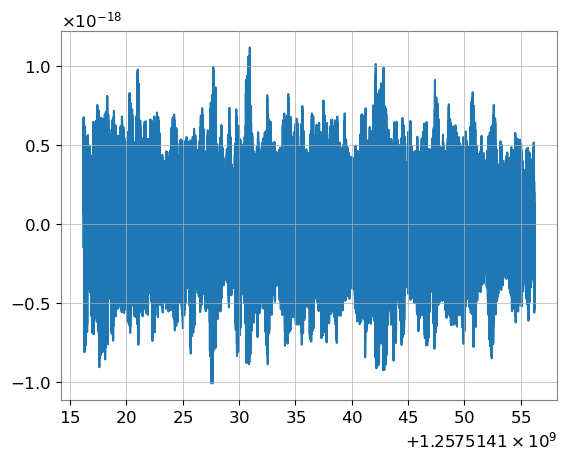

In [10]:
plt.plot(data)

CPU times: user 1min 30s, sys: 8.75 s, total: 1min 38s
Wall time: 11.8 s


[None,
 (-1.0, 1.0),
 Text(0.5, 0, 'time from 1257514136.219 [s]'),
 Text(0, 0.5, 'frequency [Hz]'),
 Text(0.5, 1.0, 'SAGE Q-transform, Q = 22.6')]

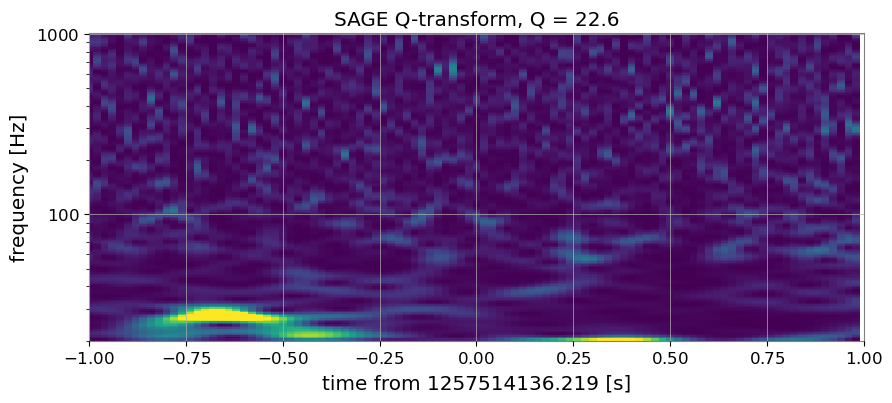

In [11]:
%%time
# SAGE Q-transform around the glitch: whiten with gwpy, then SAGE's QTransform (the same image as gwpy's q_transform)
fs = 4096
white = data.resample(fs).whiten(fduration=10)        # ASD estimated from these 10 s
white = white.crop(start + 10, end - 10)                # drop the 1 s at each end that the whitening corrupts
x = torch.tensor(white.value)

qt = QTransform(fs, x.numel(), qrange=(4, 64), frange=(20, 1000), logf=True, fres=200)
qscan, q = qt(x, return_q=True)                        # (time, frequency), median-normalised energy

t0 = df['GPStime'].iloc[0]
fig, ax = plt.subplots(figsize=(10, 4))
ax.pcolormesh(qt.times + (start + 1 - t0), qt.frequencies, qscan.T, shading="auto", vmin=0, vmax=25)
ax.set(yscale="log", xlim=(-1, 1), xlabel=f"time from {t0} [s]", ylabel="frequency [Hz]",
       title=f"SAGE Q-transform, Q = {float(q):.1f}")